<a href="https://colab.research.google.com/github/priyaaaww/ITA06_LAB_EXP/blob/main/EXP_19.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset Shape: (8128, 12)

First 5 Rows:
                           name  year  selling_price  km_driven    fuel  \
0        Maruti Swift Dzire VDI  2014         450000     145500  Diesel   
1  Skoda Rapid 1.5 TDI Ambition  2014         370000     120000  Diesel   
2      Honda City 2017-2020 EXi  2006         158000     140000  Petrol   
3     Hyundai i20 Sportz Diesel  2010         225000     127000  Diesel   
4        Maruti Swift VXI BSIII  2007         130000     120000  Petrol   

  seller_type transmission         owner  mileage(km/ltr/kg)  engine  \
0  Individual       Manual   First Owner               23.40  1248.0   
1  Individual       Manual  Second Owner               21.14  1498.0   
2  Individual       Manual   Third Owner               17.70  1497.0   
3  Individual       Manual   First Owner               23.00  1396.0   
4  Individual       Manual   First Owner               16.10  1298.0   

  max_power  seats  
0        74    5.0  
1    103.52    5.0  
2        78 

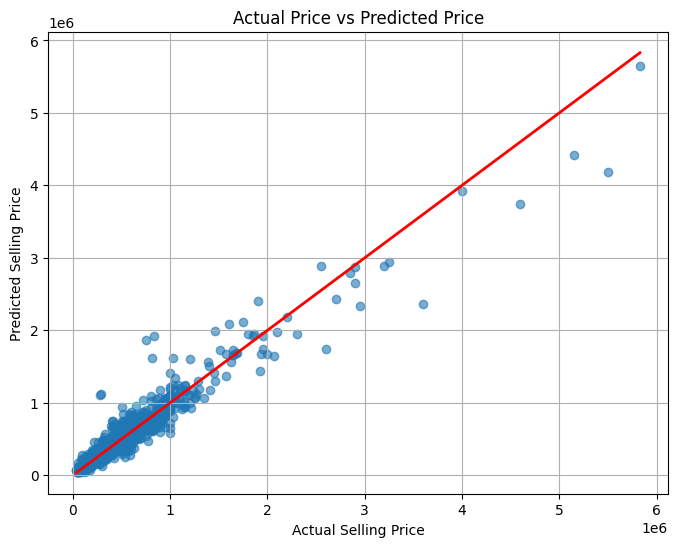

In [1]:
# Car Price Prediction using Random Forest Regression

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# -------------------------------------------------
# 1. Load the dataset
# -------------------------------------------------
df = pd.read_csv("/content/cardekho.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
print(df.head())

# -------------------------------------------------
# 2. Data preprocessing
# -------------------------------------------------

# Convert max_power to numeric.
# Invalid values, if any, are converted to NaN.
df["max_power"] = pd.to_numeric(df["max_power"], errors="coerce")

# Extract car brand from the name column
df["brand"] = df["name"].str.split().str[0]

# Remove the original name column because it has many unique values
df = df.drop(columns=["name"])

# Remove duplicate records
df = df.drop_duplicates()

# -------------------------------------------------
# 3. Select features and target
# -------------------------------------------------
X = df.drop(columns=["selling_price"])
y = df["selling_price"]

# Identify numerical and categorical columns
numerical_columns = X.select_dtypes(include=["int64", "float64"]).columns
categorical_columns = X.select_dtypes(include=["object"]).columns

print("\nNumerical Columns:")
print(list(numerical_columns))

print("\nCategorical Columns:")
print(list(categorical_columns))

# -------------------------------------------------
# 4. Create preprocessing pipelines
# -------------------------------------------------

# Fill missing numerical values with the median
numerical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

# Fill missing categorical values and apply one-hot encoding
categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", numerical_pipeline, numerical_columns),
        ("categorical", categorical_pipeline, categorical_columns)
    ]
)

# -------------------------------------------------
# 5. Create Random Forest model
# -------------------------------------------------
model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Create complete preprocessing and model pipeline
car_price_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ]
)

# -------------------------------------------------
# 6. Split the dataset
# -------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# -------------------------------------------------
# 7. Train the model
# -------------------------------------------------
car_price_model.fit(X_train, y_train)

# -------------------------------------------------
# 8. Make predictions
# -------------------------------------------------
y_pred = car_price_model.predict(X_test)

# -------------------------------------------------
# 9. Evaluate the model
# -------------------------------------------------
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nMODEL PERFORMANCE")
print("Mean Absolute Error :", round(mae, 2))
print("Mean Squared Error  :", round(mse, 2))
print("Root Mean Squared Error:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

# -------------------------------------------------
# 10. Display actual and predicted prices
# -------------------------------------------------
results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

print("\nActual and Predicted Prices:")
print(results.head(10))

# -------------------------------------------------
# 11. Plot actual vs predicted prices
# -------------------------------------------------
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6)

minimum_price = min(y_test.min(), y_pred.min())
maximum_price = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum_price, maximum_price],
    [minimum_price, maximum_price],
    color="red",
    linewidth=2
)

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Actual Price vs Predicted Price")
plt.grid(True)
plt.show()